Load the cleaned dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Dataset/Cleaned/production_data_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (429394, 13)


Analyse downtime by machine

In [2]:
downtime_analysis = (
    df[df["operating_status"] == "downtime"]
    .groupby("machine_id")["duration_minutes"]
    .sum()
    .sort_values(ascending=False)
)

print(downtime_analysis)

machine_id
s_1    83601.578367
s_2    34427.323133
s_3    27977.815933
s_4    21503.014767
s_5    21336.453150
Name: duration_minutes, dtype: float64


Result = Machine s_1 has the highest recorded downtime, approximately 1,393 hours.


#### Visualize downtime by machine

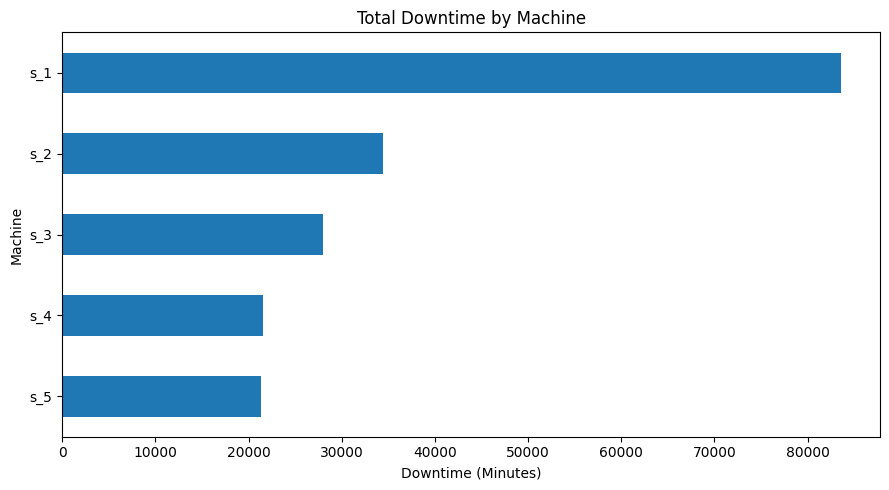

In [3]:
downtime_analysis.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Total Downtime by Machine"
)

plt.xlabel("Downtime (Minutes)")
plt.ylabel("Machine")
plt.tight_layout()
plt.show()

Now we need to identify which machine spends the most time in performance loss.

In [4]:
performance_loss = (
    df[df["operating_status"] == "performance_loss"]
    .groupby("machine_id")["duration_minutes"]
    .sum()
    .sort_values(ascending=False)
)

print(performance_loss)

machine_id
s_1    92444.285167
s_4    92406.034983
s_5    62599.651583
s_2    21801.781733
s_3    18318.196550
Name: duration_minutes, dtype: float64


Result = Machine s_1 also has the highest performance-loss duration.

### Compare downtime and performance loss

In [5]:
machine_comparison = pd.DataFrame({
    "Downtime_Minutes": downtime_analysis,
    "Performance_Loss_Minutes": performance_loss
})

machine_comparison["Total_Loss_Minutes"] = (
    machine_comparison["Downtime_Minutes"] +
    machine_comparison["Performance_Loss_Minutes"]
)

machine_comparison = machine_comparison.sort_values(
    "Total_Loss_Minutes", ascending=False
)

print(machine_comparison.round(2))

            Downtime_Minutes  Performance_Loss_Minutes  Total_Loss_Minutes
machine_id                                                                
s_1                 83601.58                  92444.29           176045.86
s_4                 21503.01                  92406.03           113909.05
s_5                 21336.45                  62599.65            83936.10
s_2                 34427.32                  21801.78            56229.10
s_3                 27977.82                  18318.20            46296.01


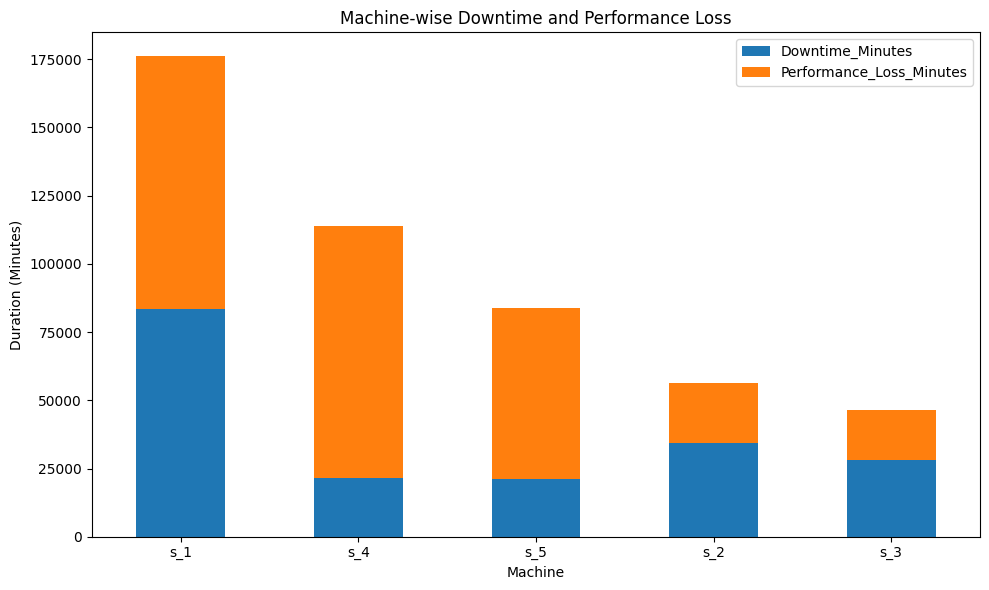

In [6]:
machine_comparison[
    ["Downtime_Minutes", "Performance_Loss_Minutes"]
].plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    title="Machine-wise Downtime and Performance Loss"
)

plt.xlabel("Machine")
plt.ylabel("Duration (Minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Result: Machine s_1 has the highest combined production loss, followed by s_4 and s_5. Machine s_3 has the lowest combined loss.

#### Best Performing Machine

In [7]:
production_time = df.pivot_table(
    index="machine_id",
    columns="operating_status",
    values="duration_minutes",
    aggfunc="sum",
    fill_value=0
)

production_percentage = (
    production_time["production"] /
    production_time.sum(axis=1) * 100
).reset_index(name="Production_Percentage")

print(production_percentage.sort_values(
    "Production_Percentage", ascending=False
))

  machine_id  Production_Percentage
0        s_1              57.250340
4        s_5              44.585680
2        s_3              40.551269
3        s_4              36.704665
1        s_2              24.517020


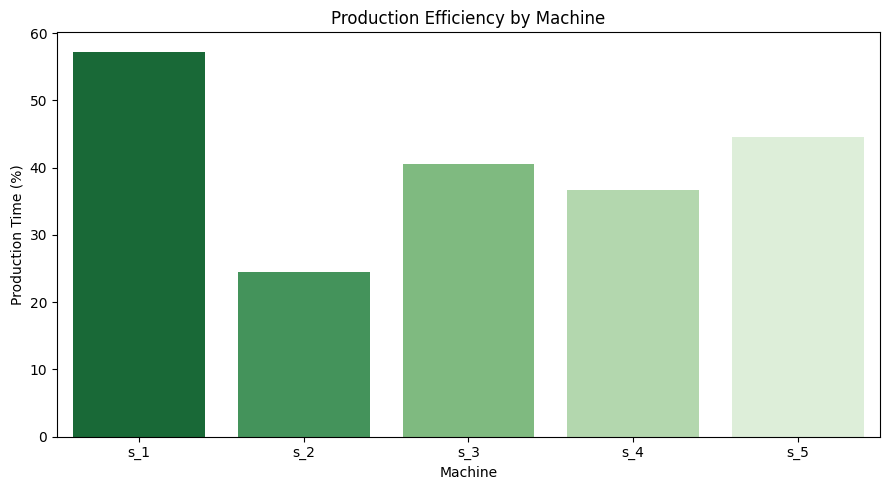

In [8]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=production_percentage,
    x="machine_id",
    y="Production_Percentage",
    hue="machine_id",
    palette="Greens_r",
    legend=False
)

plt.title("Production Efficiency by Machine")
plt.xlabel("Machine")
plt.ylabel("Production Time (%)")
plt.tight_layout()
plt.show()

Result: Machine s_1 has the highest production-time percentage at approximately 57%, followed by s_5 at 44%. Machine s_2 has the lowest production-time percentage at approximately 24%.

#### Monthly Downtime Trend by Machine

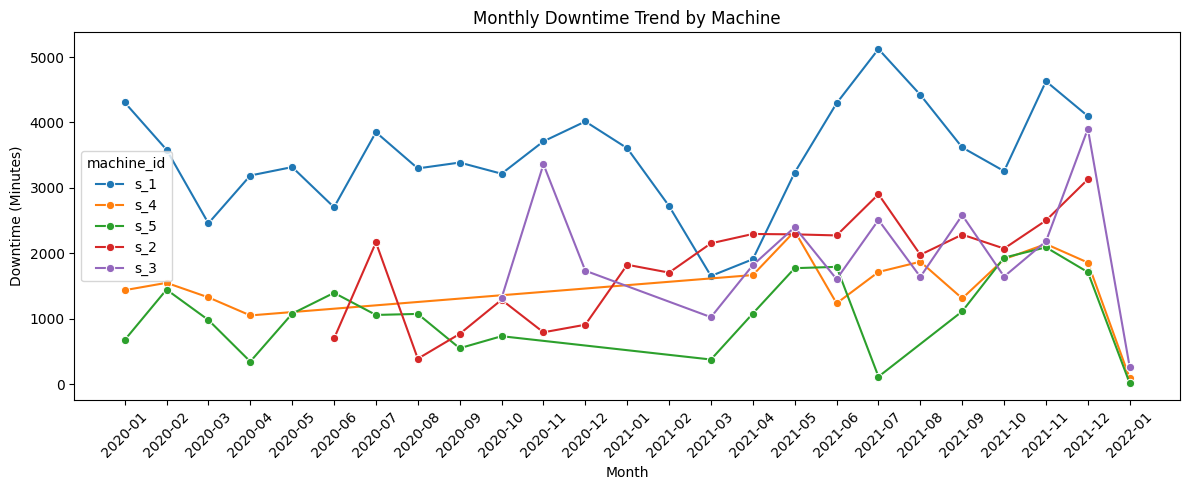

In [9]:
# Convert date column
df["record_datetime"] = pd.to_datetime(
    df["record_datetime"], format="mixed", utc=True
)

# Extract month
df["month"] = df["record_datetime"].dt.strftime("%Y-%m")

# Calculate monthly downtime
monthly_downtime = (
    df[df["operating_status"] == "downtime"]
    .groupby(["month", "machine_id"])["duration_minutes"]
    .sum()
    .reset_index()
)

# Create line chart
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_downtime,
    x="month",
    y="duration_minutes",
    hue="machine_id",
    marker="o"
)

plt.title("Monthly Downtime Trend by Machine")
plt.xlabel("Month")
plt.ylabel("Downtime (Minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Result: Machine s_1 consistently records the highest monthly downtime across most of the period, with its highest peak in July 2021 at approximately 5,100 minutes. Machine s_3 also shows a sharp increase in November 2020 and December 2021.

#### compare how much time each machine spends in production, downtime, idle, performance loss and scheduled downtime.

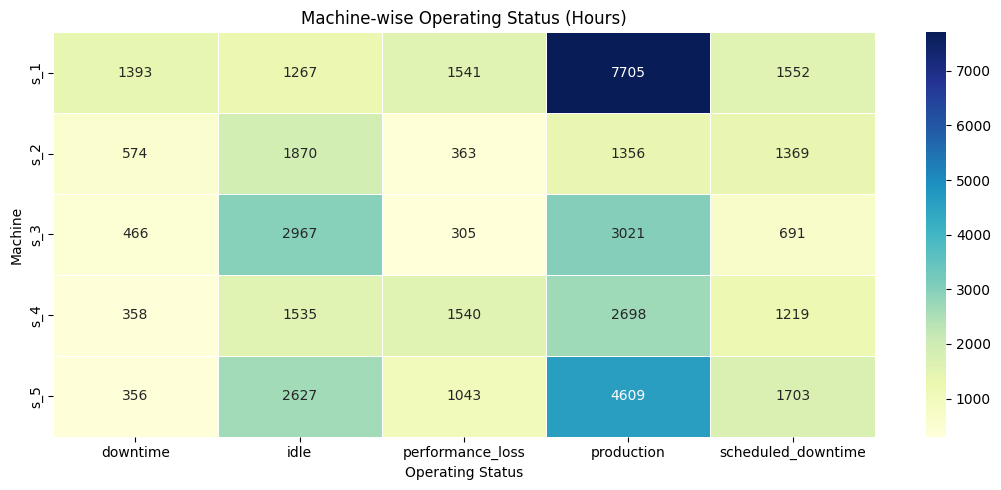

In [10]:
# Calculate total time by machine and operating status
status_analysis = df.pivot_table(
    index="machine_id",
    columns="operating_status",
    values="duration_minutes",
    aggfunc="sum"
) / 60

# Create heatmap
plt.figure(figsize=(11, 5))

sns.heatmap(
    status_analysis,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Machine-wise Operating Status (Hours)")
plt.xlabel("Operating Status")
plt.ylabel("Machine")
plt.tight_layout()
plt.show()

Result: Machine s_1 has the highest production time (7,705 hours) and also records the highest downtime (1,393 hours). Machine s_5 has the second-highest production time (4,609 hours), while machine s_3 has the highest idle time (2,967 hours).

#### We want to identify which machine operates at the highest average production speed during production.

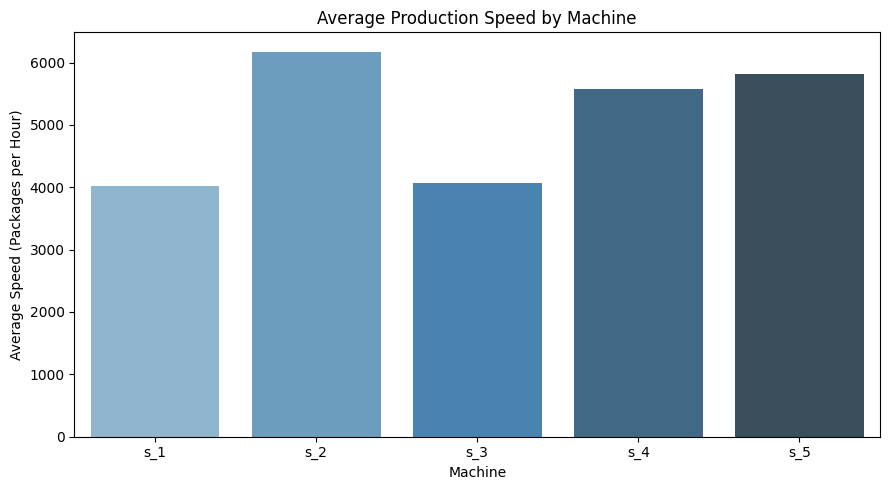

In [11]:
# Calculate average production speed during production
speed_analysis = (
    df[df["operating_status"] == "production"]
    .groupby("machine_id")["production_speed"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=speed_analysis,
    x="machine_id",
    y="production_speed",
    hue="machine_id",
    palette="Blues_d",
    legend=False
)

plt.title("Average Production Speed by Machine")
plt.xlabel("Machine")
plt.ylabel("Average Speed (Packages per Hour)")
plt.tight_layout()
plt.show()

Result: Machine s_2 has the highest average production speed at approximately 6,170 packages per hour, followed by s_5 at 5,820. Machine s_1 has the lowest average speed at approximately 4,020 packages per hour.